# Python Refresher Assignment

## Imports and Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df=pd.read_csv('data/2025_swings.csv')

df.shape # 337,397 rows and 120 columns 

# I don't want some of the columns in this dataset so I am going to select a subset of columns
df=df[['pitch_type','game_date','release_speed','player_name','batter','inning_topbot','events','zone','stand','p_throws','home_team','away_team','hit_location','bb_type','hit_distance_sc','launch_speed','launch_angle','game_pk','estimated_woba_using_speedangle','launch_speed_angle','bat_speed','swing_length','miss_distance','arm_angle','attack_angle','attack_direction','swing_path_tilt','intercept_ball_minus_batter_pos_x_inches','intercept_ball_minus_batter_pos_y_inches']]

df.shape # 337,397 rows and 29 columns now
df.head()


,pitch_type,game_date,release_speed,player_name,batter,inning_topbot,events,zone,stand,p_throws,...,launch_speed_angle,bat_speed,swing_length,miss_distance,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
0,SI,2025-03-31,96.6,"Bautista, Félix",608324,Top,field_out,2.0,R,R,...,3.0,NaN,NaN,NaN,69.1,NaN,NaN,NaN,NaN,NaN
1,SI,2025-03-31,97.8,"Bautista, Félix",646240,Top,NaN,7.0,L,R,...,NaN,73.3,7.9,NaN,73.1,2.326145,17.900737,28.548852,43.512056,18.085586
2,SI,2025-03-31,97.8,"Bautista, Félix",680776,Top,single,1.0,L,R,...,4.0,74.7,7.4,NaN,69.6,1.731196,8.476116,17.775646,46.739807,25.033825
3,SI,2025-03-31,97.8,"Bautista, Félix",671213,Top,field_out,6.0,L,R,...,2.0,75.9,7.7,NaN,69.3,5.985515,0.850822,42.665573,30.199497,22.860335
4,SI,2025-03-31,97.6,"Bautista, Félix",671213,Top,NaN,11.0,L,R,...,NaN,62.4,7.1,NaN,68.3,11.218355,7.648975,19.254296,42.368672,17.316569


## Basic Cleaning

### Remove Duplicates

In [3]:
df.duplicated().sum() # 37 duplicates

df.drop_duplicates(inplace=True) # drop duplicates

df.duplicated().sum() # 0 duplicates now

np.int64(0)

### Missing Values

In [4]:
df.isna().sum() # lots of missing values because cameras don't always pick up all data on every pitch/swing but also because some of this data is not available on swings and misses 

df['events']=df['events'].fillna('miss') # fill na values in events column to say miss to represents swing and misses

df.head()

df=df[df['attack_angle'].notna()] # drop rows where the swing data was not properly captured by the cameras
df=df[df['swing_path_tilt'].notna()]

df.isna().sum() # most camera misses have been removed

df=df[df['arm_angle'].notna()] # drop remaining missing data rows

df.isna().sum() # remaining missing data is due to either the event being a swing and miss or the ball being in play so the data doesnt apply

pitch_type                                       0
game_date                                        0
release_speed                                    0
player_name                                      0
batter                                           0
inning_topbot                                    0
events                                           0
zone                                             0
stand                                            0
p_throws                                         0
home_team                                        0
away_team                                        0
hit_location                                184031
bb_type                                     209174
hit_distance_sc                             100040
launch_speed                                100306
launch_angle                                 99924
game_pk                                          0
estimated_woba_using_speedangle             179047
launch_speed_angle             

### Data Types

In [5]:
df.dtypes # only data types that I want to change is game_date from a string to a date object and hit location and zone both from numeric to categorical

df['game_date']=pd.to_datetime(df['game_date']) 

df['hit_location']=pd.Categorical(df['hit_location'])
df['zone']=pd.Categorical(df['zone'])
df.dtypes

pitch_type                                             str
game_date                                   datetime64[us]
release_speed                                      float64
player_name                                            str
batter                                               int64
inning_topbot                                          str
events                                                 str
zone                                              category
stand                                                  str
p_throws                                               str
home_team                                              str
away_team                                              str
hit_location                                      category
bb_type                                                str
hit_distance_sc                                    float64
launch_speed                                       float64
launch_angle                                       float

## Summaries

### Numeric Summaries

In [ ]:
df.describe() # summary statistics for numeric columns

,game_date,release_speed,batter,hit_distance_sc,launch_speed,launch_angle,game_pk,estimated_woba_using_speedangle,launch_speed_angle,bat_speed,swing_length,miss_distance,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
count,327270,327270.000000,327270.000000,227230.000000,226964.000000,227346.000000,327270.000000,148223.000000,117688.000000,327270.00000,327270.000000,77038.000000,327270.000000,327270.000000,327270.000000,327270.000000,326925.000000,326925.000000
mean,2025-06-28 00:41:01.556512,89.564163,655209.110606,158.608463,82.901163,18.243303,777344.799236,0.288235,3.236906,69.90812,7.228447,3.177696,37.702656,9.250035,-0.461696,32.187069,36.979653,29.953807
min,2025-03-27 00:00:00,31.100000,455117.000000,0.000000,2.600000,-89.000000,776135.000000,0.000000,1.000000,1.30000,0.300000,0.100000,-67.400000,-86.716999,-179.789290,0.983747,6.234870,-11.999040
25%,2025-05-12 00:00:00,85.400000,642731.000000,24.000000,73.300000,-3.000000,776741.000000,0.007000,2.000000,67.40000,6.600000,0.682169,30.300000,2.017026,-12.637433,27.568635,32.076064,22.162415
50%,2025-06-27 00:00:00,90.300000,667472.000000,170.000000,82.600000,21.000000,777342.000000,0.134000,3.000000,71.30000,7.300000,1.526005,38.500000,9.469066,0.144397,32.190653,36.964153,29.273708
75%,2025-08-15 00:00:00,94.400000,681082.000000,246.000000,94.700000,42.000000,777947.000000,0.463000,4.000000,74.60000,7.900000,4.053989,46.200000,16.891588,12.169677,36.828691,41.864123,37.412582
max,2025-09-28 00:00:00,104.100000,810938.000000,493.000000,122.900000,90.000000,778562.000000,2.018000,6.000000,88.00000,12.900000,57.450888,87.100000,89.261165,179.782174,89.308154,79.324594,71.962542
std,NaN,6.032502,50042.860751,119.407216,15.194740,32.673223,699.105106,0.365036,1.291945,8.38842,0.949458,4.072962,12.901585,11.323542,19.629582,6.960327,7.153613,11.580656


### Categorical Summaries

In [7]:
df['pitch_type'].value_counts()

pitch_type
FF    106787
SL     48660
SI     47902
CH     35742
FC     25371
ST     23761
CU     19042
FS     11660
KC      5481
SV      1505
FA       397
EP       380
FO       370
CS       163
KN        47
SC         1
UN         1
Name: count, dtype: int64

In [8]:
df['events'].value_counts()

events
miss                         178284
field_out                     71128
strikeout                     30708
single                        24259
double                         7198
home_run                       5279
force_out                      3174
grounded_into_double_play      2945
sac_fly                        1237
field_error                     959
triple                          584
fielders_choice                 375
double_play                     356
fielders_choice_out             304
sac_bunt                        277
strikeout_double_play            93
catcher_interf                   70
truncated_pa                     22
sac_fly_double_play              15
triple_play                       3
Name: count, dtype: int64

In [9]:
df['hit_location'].value_counts()

hit_location
2.0    31979
8.0    20563
9.0    19056
7.0    18542
6.0    14288
4.0    13710
5.0    12391
3.0     8714
1.0     3996
Name: count, dtype: int64

In [10]:
df['zone'].value_counts()

zone
5.0     40593
14.0    35984
8.0     30195
6.0     28343
4.0     28182
13.0    27262
2.0     26788
9.0     22441
7.0     19844
1.0     18295
11.0    17291
3.0     16642
12.0    15410
Name: count, dtype: int64

In [11]:
df['stand'].value_counts()

stand
R    183273
L    143997
Name: count, dtype: int64

In [12]:
df['p_throws'].value_counts()

p_throws
R    237882
L     89388
Name: count, dtype: int64

In [13]:
df['home_team'].value_counts()

home_team
SEA    11350
COL    11328
ATL    11288
ATH    11263
BOS    11245
MIN    11220
PHI    11191
WSH    11191
TB     11155
LAD    11007
CWS    10976
MIL    10941
LAA    10921
DET    10883
TOR    10881
TEX    10875
CIN    10867
SF     10839
AZ     10812
BAL    10804
NYY    10804
MIA    10754
NYM    10734
PIT    10707
CHC    10645
CLE    10601
SD     10553
STL    10499
HOU    10492
KC     10444
Name: count, dtype: int64

In [14]:
df['away_team'].value_counts()

away_team
BOS    11246
NYY    11141
DET    11102
ATL    11081
HOU    11065
BAL    11057
PHI    11047
SEA    11041
AZ     11027
NYM    11023
TEX    11022
TB     10994
LAA    10985
CHC    10959
CLE    10955
SD     10947
TOR    10887
WSH    10866
MIN    10827
MIA    10823
COL    10787
SF     10753
STL    10743
CWS    10736
KC     10733
MIL    10700
ATH    10694
PIT    10683
CIN    10675
LAD    10671
Name: count, dtype: int64

In [15]:
df['bb_type'].value_counts()

bb_type
ground_ball    49479
fly_ball       32102
line_drive     27973
popup           8542
Name: count, dtype: int64

### Missingness Profile

In [16]:
for column in df.columns:
    print(f'{column}: {round((len(df[df[column].isna()])/len(df[column])*100),1)} % missing values')

pitch_type: 0.0 % missing values
game_date: 0.0 % missing values
release_speed: 0.0 % missing values
player_name: 0.0 % missing values
batter: 0.0 % missing values
inning_topbot: 0.0 % missing values
events: 0.0 % missing values
zone: 0.0 % missing values
stand: 0.0 % missing values
p_throws: 0.0 % missing values
home_team: 0.0 % missing values
away_team: 0.0 % missing values
hit_location: 56.2 % missing values
bb_type: 63.9 % missing values
hit_distance_sc: 30.6 % missing values
launch_speed: 30.6 % missing values
launch_angle: 30.5 % missing values
game_pk: 0.0 % missing values
estimated_woba_using_speedangle: 54.7 % missing values
launch_speed_angle: 64.0 % missing values
bat_speed: 0.0 % missing values
swing_length: 0.0 % missing values
miss_distance: 76.5 % missing values
arm_angle: 0.0 % missing values
attack_angle: 0.0 % missing values
attack_direction: 0.0 % missing values
swing_path_tilt: 0.0 % missing values
intercept_ball_minus_batter_pos_x_inches: 0.1 % missing values
inter

## Visualizations

### Histogram

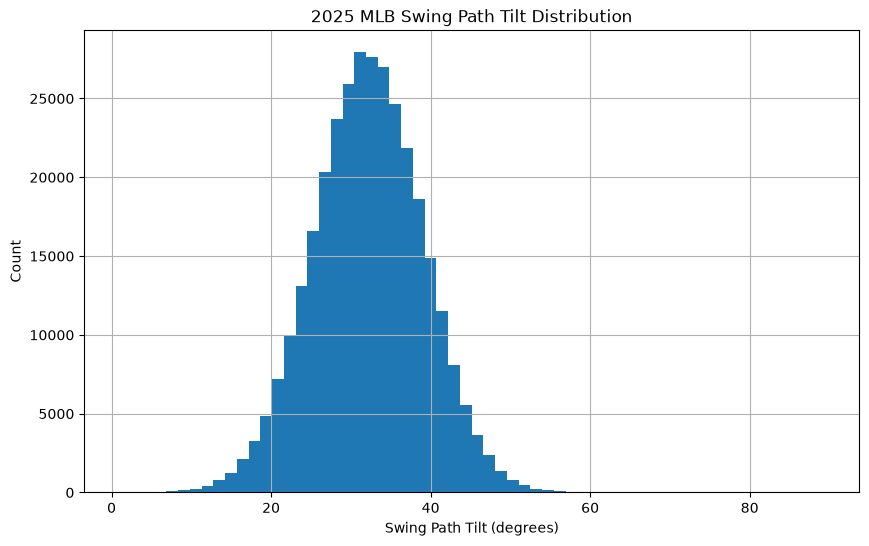

In [17]:
fig, ax=plt.subplots(figsize=(10,6))
df['swing_path_tilt'].hist(bins=60)
ax.set_title('2025 MLB Swing Path Tilt Distribution')
ax.set_xlabel('Swing Path Tilt (degrees)')
ax.set_ylabel('Count')

plt.savefig('images/histogram.png')
plt.show()

### Bar Chart

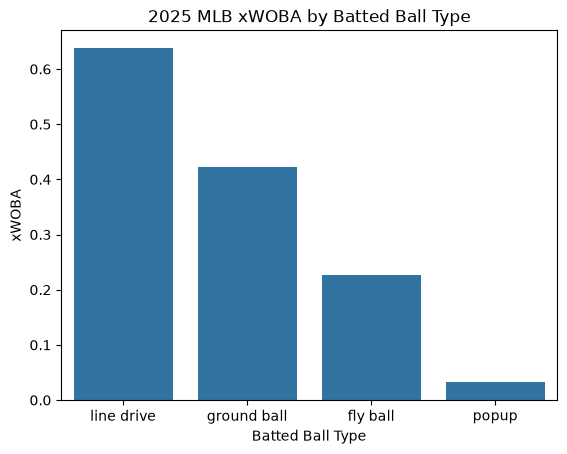

In [25]:
sorted=df.groupby('bb_type')['estimated_woba_using_speedangle'].mean().reset_index().sort_values(by='estimated_woba_using_speedangle',ascending=False)
sns.barplot(sorted,x='bb_type',y='estimated_woba_using_speedangle')
plt.title('2025 MLB xWOBA by Batted Ball Type')
plt.xlabel('Batted Ball Type')
plt.ylabel('xWOBA')
plt.xticks(ticks=[0,1,2,3] ,labels=['line drive','ground ball','fly ball','popup'])

plt.savefig('images/barchart.png')
plt.show()

### Plot

In [19]:
df['month']=df['game_date'].dt.month

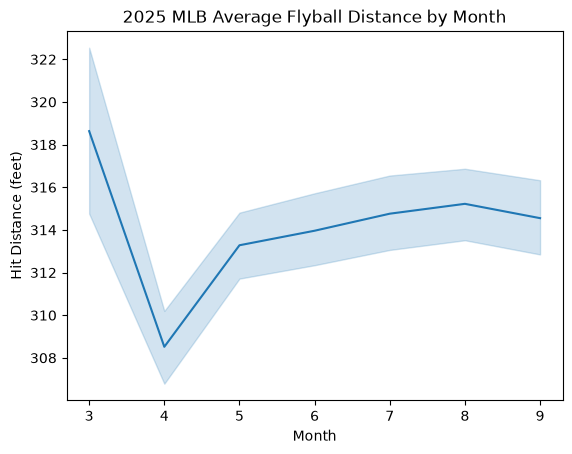

In [21]:
flyballs=df[df['bb_type']=='fly_ball']
sns.lineplot(flyballs,x='month',y='hit_distance_sc')
plt.title('2025 MLB Average Flyball Distance by Month')
plt.xlabel('Month')
plt.ylabel('Hit Distance (feet)')

plt.savefig('images/lineplot.png')
plt.show()

## Reflection

### This assignment for me was all review and didn't present many challenges. My process was to go through each step and make sure I met all requirements from the assignment instructions. The most difficult part in the data analysis was deciding how to handle missing values since there were so many and in this data missingness had a meaning in many cases. The most difficult part overall was actually the README file as I haven't been shown how to or had to write one before. This was a good refresher assignment to get back into Python and a reminder of the initial process of exploratory data analysis. 